In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from skimage import io, filters, morphology, measure, segmentation
from skimage.feature import peak_local_max
from scipy import ndimage as ndi

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report

Image shape: (512, 512)
Data type: uint16


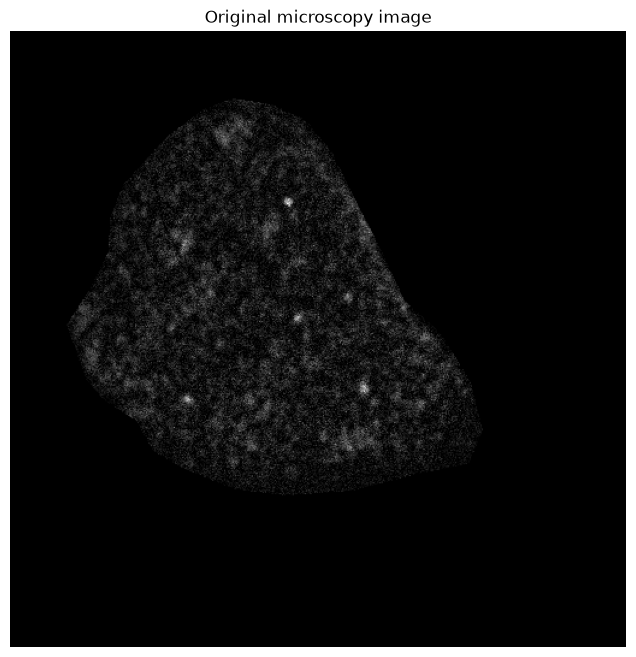

In [2]:
image_path = "test.tif"

image = io.imread(image_path)

print("Image shape:", image.shape)
print("Data type:", image.dtype)

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(image, cmap="gray")
ax.set_title("Original microscopy image")
ax.axis("off")

plt.show()

In [4]:
df = pd.read_csv("test.csv")

In [5]:
df

,id,x_nm,y_nm,sigma_nm,intensity_photon,x_pixel,y_pixel,sigma_pixel,foci_MFI,foci_SD
0,3.0,3525.276548,13606.820578,86.880850,309.867164,56.261748,231.457369,1.509803,7.142857,4.611432
1,4.0,3426.744405,14489.594479,95.419255,230.042437,54.549471,246.798086,1.658182,8.222222,3.644715
2,5.0,3593.493377,14143.423979,203.208099,980.417462,57.447210,240.782385,3.531321,9.526316,3.400749
3,6.0,3832.211099,15629.001269,110.955359,433.927192,61.595613,266.598533,1.928166,6.083333,4.751462
4,7.0,3753.033031,13521.815213,97.273987,291.823974,60.219668,229.980158,1.690413,14.777778,1.617802
...,...,...,...,...,...,...,...,...,...,...
268,728.0,20710.330241,17820.648646,99.496542,233.199913,354.901137,304.684666,1.729037,5.600000,4.409082
269,729.0,20873.584669,16410.864279,75.529430,121.374221,357.738149,280.185636,1.312540,12.500000,3.095696
270,731.0,20905.530569,19733.277326,78.142158,162.940722,358.293300,337.922052,1.357943,7.428571,3.658928
271,738.0,21410.923265,16346.321883,111.289449,370.094183,367.075941,279.064028,1.933972,7.100000,3.176476


In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

def show_one_focus(image, df, index, radius_factor=2, padding=30):

    # Select focus by DataFrame index
    row = df.loc[index]

    x = float(row["x_pixel"])
    y = float(row["y_pixel"])
    sigma = float(row["sigma_pixel"])
    sigma_nm = float(row["sigma_nm"])
    foci_MFI = float(row["foci_MFI"])

    # Radius based on sigma
    radius = radius_factor * sigma

    H, W = image.shape[:2]

    # Crop around the focus
    margin = max(padding, int(np.ceil(radius + 10)))

    x0 = max(0, int(x - margin))
    x1 = min(W, int(x + margin + 1))
    y0 = max(0, int(y - margin))
    y1 = min(H, int(y + margin + 1))

    crop = image[y0:y1, x0:x1]

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    # Original image
    axes[0].imshow(crop, cmap="gray")
    axes[0].set_title(f"Index: {index}")

    # Image with focus boundary
    axes[1].imshow(crop, cmap="gray")

    circle = Circle(
        (x - x0, y - y0),
        radius=radius,
        edgecolor="red",
        facecolor="none",
        linewidth=1.5
    )

    axes[1].add_patch(circle)

    axes[1].set_title(
        f"Index: {index}\n"
        f"Sigma, nm: {sigma_nm:.2f} nm\n"
        f"Foci MFI: {foci_MFI:.2f}",
    )

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

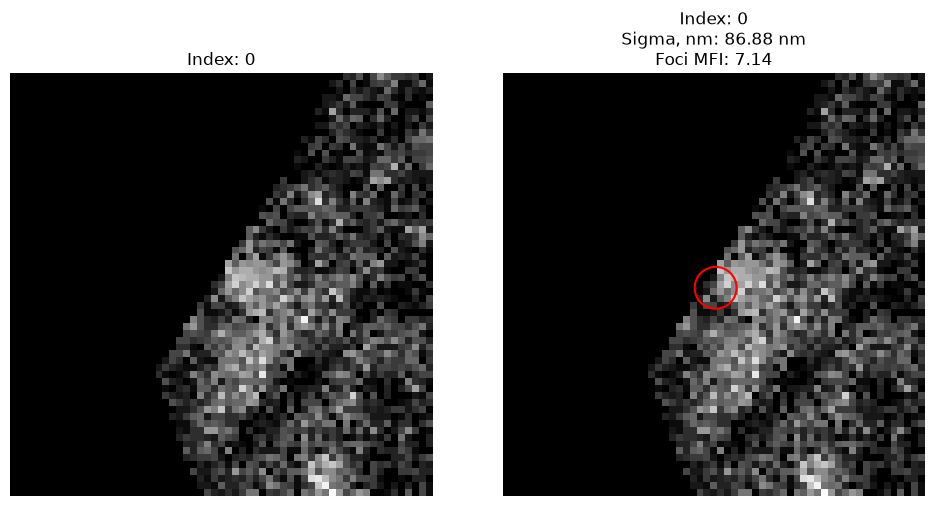

In [17]:
show_one_focus(image, df, index=0)

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

def show_foci_range(
    image,
    df,
    start=0,
    end=10,
    radius_factor=2,
    padding=30
):
    # Select foci by DataFrame index (inclusive)
    subset = df.loc[start:end]

    if subset.empty:
        print("No foci found in this index range.")
        return

    n = len(subset)

    # Two columns: original and annotated
    fig, axes = plt.subplots(
        n, 2,
        figsize=(10, n * 4),
        squeeze=False
    )

    H, W = image.shape[:2]

    for i, (index, row) in enumerate(subset.iterrows()):

        x = float(row["x_pixel"])
        y = float(row["y_pixel"])
        sigma = float(row["sigma_pixel"])
        sigma_nm = float(row["sigma_nm"])
        foci_MFI = float(row["foci_MFI"])

        radius = radius_factor * sigma

        # Crop around focus
        margin = max(padding, int(np.ceil(radius + 10)))

        x0 = max(0, int(np.floor(x - margin)))
        x1 = min(W, int(np.ceil(x + margin + 1)))
        y0 = max(0, int(np.floor(y - margin)))
        y1 = min(H, int(np.ceil(y + margin + 1)))

        crop = image[y0:y1, x0:x1]

        ax1, ax2 = axes[i]

        # Original microscopy image
        ax1.imshow(crop, cmap="gray")
        ax1.set_title(f"Index: {index}")
        ax1.axis("off")

        # Image with focus circle
        ax2.imshow(crop, cmap="gray")

        circle = Circle(
            (x - x0, y - y0),
            radius=radius,
            edgecolor="red",
            facecolor="none",
            linewidth=1.5
        )

        ax2.add_patch(circle)

        ax2.set_title(
            f"Index: {index}\n"
            f"Sigma: {sigma_nm:.2f} nm\n"
            f"Foci MFI: {foci_MFI:.2f}",
            fontsize=10
        )

        ax2.axis("off")

    plt.tight_layout()
    plt.show()

In [22]:
df.loc[0:10]

,id,x_nm,y_nm,sigma_nm,intensity_photon,x_pixel,y_pixel,sigma_pixel,foci_MFI,foci_SD
0,3.0,3525.276548,13606.820578,86.880850,309.867164,56.261748,231.457369,1.509803,7.142857,4.611432
1,4.0,3426.744405,14489.594479,95.419255,230.042437,54.549471,246.798086,1.658182,8.222222,3.644715
2,5.0,3593.493377,14143.423979,203.208099,980.417462,57.447210,240.782385,3.531321,9.526316,3.400749
3,6.0,3832.211099,15629.001269,110.955359,433.927192,61.595613,266.598533,1.928166,6.083333,4.751462
4,7.0,3753.033031,13521.815213,97.273987,291.823974,60.219668,229.980158,1.690413,14.777778,1.617802
5,9.0,4073.929339,15960.421115,188.574352,1102.988950,65.796157,272.357900,3.277018,11.685714,5.063999
6,11.0,4204.823660,12893.944673,92.962339,156.313026,68.070820,219.069114,1.615486,6.222222,3.488960
7,12.0,4199.861176,15243.357726,107.780270,216.957336,67.984583,259.896876,1.872990,6.111111,5.566656
8,14.0,4242.944295,13653.602295,103.338574,194.000780,68.733275,232.270335,1.795803,8.454545,3.551277
9,16.0,4516.667372,17027.096913,116.443880,365.957137,73.489995,290.894438,2.023545,5.357143,3.497083


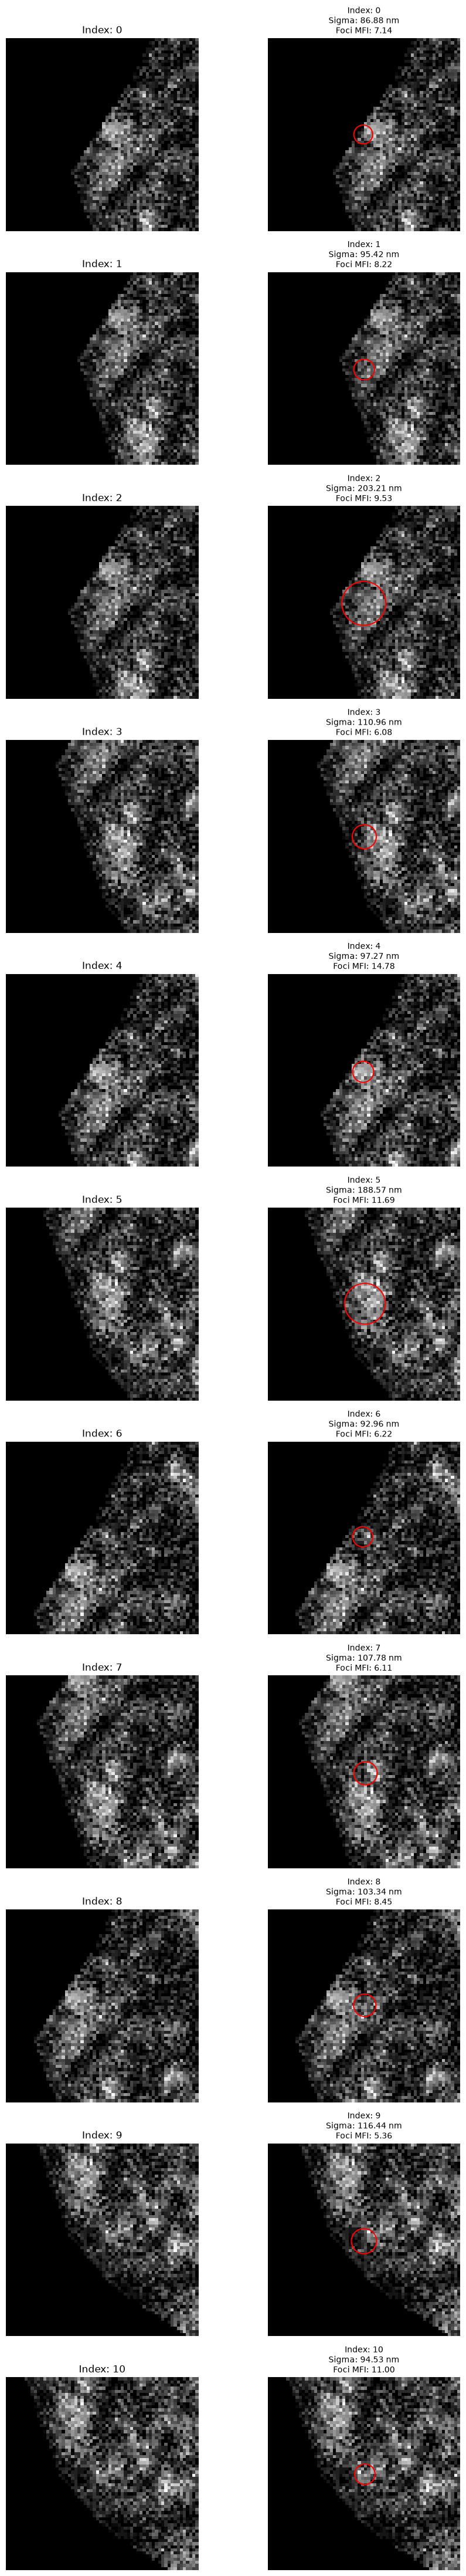

In [19]:
show_foci_range(image, df, start=0, end=10)